<a href="https://colab.research.google.com/github/Swalha14/SemProject_MLEngine/blob/main/RidgeRegression_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Elimisha: Mathematics Grade Prediction Using Ridge Regression

### Project Deliverable 2 (CAT 2)

## 1. Introduction

Elimisha is an educational platform intended to support learners through curriculum-aligned resources and data-driven academic support. This notebook focuses on developing a machine learning model to predict students' final Mathematics grades using the UCI Student Performance dataset.

The task is formulated as a supervised regression problem, where the final Mathematics grade (G3) is the target variable. Ridge Regression is selected as the base model because it applies regularisation to help control overfitting.

This notebook documents the exploratory data analysis, data cleaning, preparation of the modelling dataset, model training, evaluation, and proposed methods for further validation.

The model will be evaluated using actual results from the data. Its performance will not be assumed before testing.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

Saving student-mat.csv to student-mat.csv


**2. EDA-Exploratory Data Analysis**

In [ ]:
df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

Dataset shape: (395, 33)

First five rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


Inspecting the dataset


2.1 Checking the structure


In [ ]:
# Display all column names and their data types
print("Column names and data types:")
df.info()


Column names and data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-n

2.2 Check missing values


In [ ]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values per column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Total missing values: 0


2.3 Check for duplicates


In [ ]:
# Check for completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


2.4 : Numerical Summaries

In [ ]:
# Summarise numerical columns
display(df.describe())

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


2.5 : Examining Target Variable (Final Math Grade, G3)

G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64


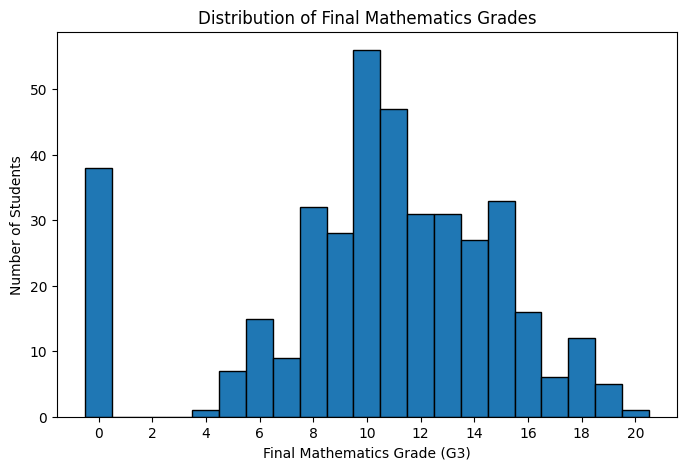

In [ ]:
# Display the distribution of final Mathematics grades
print(df["G3"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
plt.hist(df["G3"], bins=np.arange(-0.5, 21.5, 1), edgecolor="black")
plt.xlabel("Final Mathematics Grade (G3)")
plt.ylabel("Number of Students")
plt.title("Distribution of Final Mathematics Grades")
plt.xticks(range(0, 21, 2))
plt.show()

2.6 Intial Data Quality Findings

The dataset contains 395 student records and 33 columns. The columns consist of 16 integer variables and 17 categorical variables stored as object data types.

The missing-value check identified no missing values in any column. The duplicate check also found no completely duplicated rows. Therefore, no rows need to be removed due to missing values or exact duplication at this stage.

**Observation 1: Distribution of Final Mathematics Grades**

The most frequent final Mathematics grade is 10, recorded by 56 students. The grades range from 0 to 20, showing that the dataset contains students with different levels of final Mathematics performance.

2.7: Examining relationships between selected variables

This analysis examines how selected academic and non-academic factors relate to G3, the final Mathematics grade.

Academic factors: G1 and G2 (previous grades), studytime (study habits), and failures (previous class failures).

Non-academic factors: absences (attendance), activities (extracurricular participation), and romantic (relationship status).

Numerical correlations and group grade averages are used to explore these relationships. The findings indicate associations, not causation.

In [ ]:
# Examine correlations between selected numerical variables
selected_columns = [
    "G1", "G2", "G3",
    "studytime", "failures", "absences"
]

correlations = (
    df[selected_columns]
    .corr()["G3"]
    .sort_values(ascending=False)
)

print("Correlation of selected numerical variables with G3:")
display(correlations)

# Compare final grades by participation in activities
print("\nFinal grades by participation in activities:")
display(
    df.groupby("activities")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

# Compare final grades by romantic relationship status
print("\nFinal grades by romantic relationship status:")
display(
    df.groupby("romantic")["G3"]
    .agg(["count", "mean", "median"])
    .round(2)
)

Correlation of selected numerical variables with G3:


,G3
G3,1.000000
G2,0.904868
G1,0.801468
studytime,0.097820
absences,0.034247
failures,-0.360415



Final grades by participation in activities:


,count,mean,median
activities,,,
no,194,10.34,11.0
yes,201,10.49,11.0



Final grades by romantic relationship status:


,count,mean,median
romantic,,,
no,263,10.84,11.0
yes,132,9.58,11.0


**Observation 2: Relationship Between Previous and Final Grades**

G2 has a strong positive correlation with G3 (0.905), while G1 also has a strong positive correlation (0.801). This indicates that students with higher previous Mathematics grades tend to have higher final grades in this dataset.


**Observation 3: Relationship Between Study Time, Absences, Previous Failures and Final Grade**

Studytime has a very weak positive correlation with G3 (0.098), indicating that students who spend more time studying tend to have slightly higher final Mathematics grades.

Absences has an almost zero positive correlation (0.034), suggesting virtually no linear relationship between school absences and final grades.

Failures has a negative correlation (-0.360), indicating that students with more previous class failures tend to achieve lower final Mathematics grades. Previous failures show a stronger relationship with G3 than study time or absences.

**Observation 4: Relationship Between Extracurricular Activities, Romantic Relationships and Final Grade**

Students participating in extracurricular activities have a mean G3 of 10.49, compared with 10.34 for those who do not participate. The small difference suggests similar average final grades between the groups.

Students reporting a romantic relationship have a mean G3 of 9.58, compared with 10.84 for those who do not. This shows a difference in average final grades between the groups, but it does not establish that relationship status causes lower grades.

**2.8 Checking Value Ranges and Categorical Values**

Numerical variables are checked for their minimum and maximum values to identify potentially unusual values.

Categorical variables are examined to understand their possible values and identify any unexpected entries.

These checks help determine whether additional data cleaning is necessary before modelling.

In [ ]:
# Check minimum and maximum values of numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns

print("Minimum and maximum values of numerical columns:")
display(df[numeric_columns].agg(["min", "max"]).T)

# Check the unique values in categorical columns
categorical_columns = df.select_dtypes(include="object").columns

print("\nUnique values in categorical columns:")
for column in categorical_columns:
    print(f"\n{column}: {sorted(df[column].unique())}")

Minimum and maximum values of numerical columns:


,min,max
age,15,22
Medu,0,4
Fedu,0,4
traveltime,1,4
studytime,1,4
failures,0,3
famrel,1,5
freetime,1,5
goout,1,5
Dalc,1,5



Unique values in categorical columns:

school: ['GP', 'MS']

sex: ['F', 'M']

address: ['R', 'U']

famsize: ['GT3', 'LE3']

Pstatus: ['A', 'T']

Mjob: ['at_home', 'health', 'other', 'services', 'teacher']

Fjob: ['at_home', 'health', 'other', 'services', 'teacher']

reason: ['course', 'home', 'other', 'reputation']

guardian: ['father', 'mother', 'other']

schoolsup: ['no', 'yes']

famsup: ['no', 'yes']

paid: ['no', 'yes']

activities: ['no', 'yes']

nursery: ['no', 'yes']

higher: ['no', 'yes']

internet: ['no', 'yes']

romantic: ['no', 'yes']


**Observation 5: Numerical Ranges and Categorical Values**

The numerical variables generally fall within their expected ranges, while the categorical variables contain consistent values. However, absences range from 0 to 75, with the maximum value requiring further investigation to determine whether it represents an unusual but valid record.

**Checking how many students have unusually high absences**

In [ ]:
print("Absences summary:")
display(df["absences"].describe())

print("\nStudents with more than 20 absences:")
display(
    df.loc[df["absences"] > 20, ["age", "absences", "G1", "G2", "G3"]]
    .sort_values("absences", ascending=False)
)

Absences summary:


,absences
count,395.000000
mean,5.708861
std,8.003096
min,0.000000
25%,0.000000
50%,4.000000
75%,8.000000
max,75.000000



Students with more than 20 absences:


,age,absences,G1,G2,G3
276,18,75,10,9,9
183,17,56,9,9,8
74,16,54,11,12,11
315,19,40,13,11,11
307,19,38,8,9,8
280,17,30,8,8,8
205,17,28,10,9,9
103,15,26,7,6,6
40,16,25,7,10,11
198,17,24,18,18,18


**Observation 6: Investigating unusual high absences**

The absences column has a mean of 5.71 and a median of 4, while the maximum is 75. Fifteen students have more than 20 absences, indicating a small number of unusually high values.

However, these values cannot be confirmed as errors from the available information, so they will not be removed without further justification.

3. **Data Cleaning and Preparation for Ridge Regression**

The dataset contained no missing values or exact duplicate rows, so no records were removed for these reasons. Although some students had unusually high absence counts, these values could not be confirmed as errors and were retained to avoid removing potentially valid information.

**3.1 Selecting Features and the Target Variable**

The target variable is G3, representing the student's final Mathematics grade.

 The remaining 32 columns will initially be treated as input features (X) for predicting G3 (y). The features will be reviewed and prepared for modelling, including the encoding of categorical variables and scaling of numerical features.

In [11]:
# Separate input features from the target variable
X = df.drop(columns=["G3"])
y = df["G3"]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nFirst five target values:")
display(y.head())

Feature dataset shape: (395, 32)
Target dataset shape: (395,)

Feature columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

First five target values:


,G3
0,6
1,6
2,10
3,15
4,10


**3.2 Identifying Numerical and Categorical Features**

The input features contain both numerical and categorical variables. Numerical features represent quantities or coded values, while categorical features represent groups or labels.

Identifying these types allows each to be processed appropriately before model training.



In [12]:
# Identify numerical and categorical features
numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Number of numerical features:", len(numerical_features))
print("Numerical features:")
print(numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)

Number of numerical features: 15
Numerical features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Number of categorical features: 17
Categorical features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


**3.3 Splitting the Data into Training and Testing Sets**

The data is divided into training and testing sets using an 80:20 ratio.

The training set is used to fit the model, while the testing set is reserved for evaluating its predictive performance on unseen records.

 A fixed random state ensures that the split can be reproduced.We used 42.

In [13]:
from sklearn.model_selection import train_test_split

# Split the features and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (316, 32)
Testing features: (79, 32)
Training target: (316,)
Testing target: (79,)


**3.4 Preprocessing Numerical and Categorical Features**

As Ridge Regression requires numerical inputs,numerical features will therefore be standardised, while categorical features will be converted into numerical form using one-hot encoding.

A preprocessing pipeline will ensure that these transformations are fitted using only the training data and then applied to the test data.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Scale numerical features and encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


**3.5 Creating the Ridge Regression Pipeline**

A machine-learning pipeline is created to combine preprocessing and Ridge Regression into one workflow.

 The pipeline scales numerical features, encodes categorical features, and then trains the regression model.

 Combining these steps ensures that the same preprocessing is applied consistently during training and prediction.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

# Create a pipeline combining preprocessing and Ridge Regression
ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=1.0))
    ]
)

print("Ridge Regression pipeline created successfully.")

Ridge Regression pipeline created successfully.


**3.6 Training the Ridge Regression Model**

The Ridge Regression pipeline is fitted using the training data.

During this process, the preprocessing steps learn the required transformations from the training features, and the Ridge Regression model learns the relationships between the input features and the final Mathematics grade (G3).

In [16]:
# Train the Ridge Regression pipeline
ridge_pipeline.fit(X_train, y_train)

print("Ridge Regression model trained successfully.")

Ridge Regression model trained successfully.


3.7 Evaluating the Model on Test Data

The trained model is used to predict final Mathematics grades for the testing set.


In [17]:
# Predict final Mathematics grades for the test set
y_pred = ridge_pipeline.predict(X_test)

print("First 10 actual grades:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted grades:")
print(np.round(y_pred[:10], 2))

First 10 actual grades:
[10, 12, 5, 10, 9, 13, 18, 6, 0, 14]

First 10 predicted grades:
[ 6.03 11.54  2.84  8.79  8.56 11.9  19.09  7.2   7.41 12.29]


**3.8 Evaluating Predictive Performance Using Regression Metrics**

Three regression metrics are used to evaluate the model: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

 MAE measures the average absolute difference between actual and predicted grades. RMSE gives greater weight to larger prediction errors, while R² indicates how much variation in the target grades is explained by the model.

  These metrics help assess the model's predictive performance on the unseen testing data.

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R² Score: {r2:.3f}")

Mean Absolute Error (MAE): 1.639
Root Mean Squared Error (RMSE): 2.372
R² Score: 0.726


**3.9 Visualising Actual and Predicted Grades**

A scatter plot is used to compare actual final Mathematics grades with the grades predicted by the Ridge Regression model.

 A reference line represents perfect predictions, where the predicted grade equals the actual grade.

  Points closer to this line indicate more accurate predictions, while points farther away represent larger prediction errors.

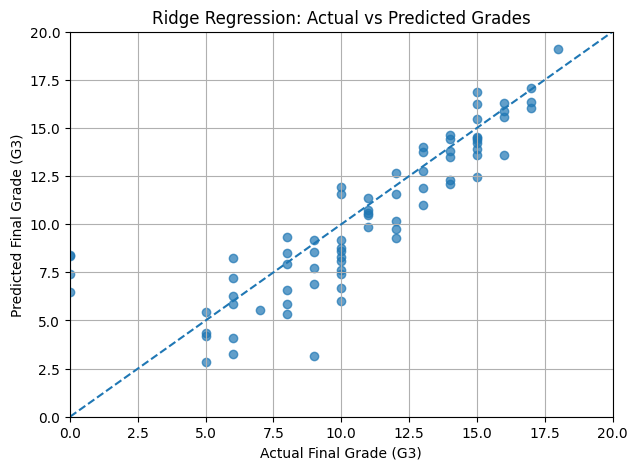

In [19]:
# Plot actual grades against predicted grades
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Reference line for perfect predictions
plt.plot([0, 20], [0, 20], linestyle="--")

plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade (G3)")
plt.title("Ridge Regression: Actual vs Predicted Grades")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.grid(True)
plt.show()

**Observation:** The scatter plot shows a generally positive relationship between actual and predicted final Mathematics grades. Many points lie relatively close to the reference line, indicating that the model predicts several grades reasonably well.

 However, some points deviate considerably from the line, showing that prediction errors vary across students.

 Overall, the plot suggests that the baseline Ridge Regression model captures important patterns in the data, although its predictions are not perfectly accurate.

**3.10 Validating the Ridge Regression Model Using Five-Fold Cross-Validation**

Five-fold cross-validation is used to assess the consistency of the Ridge Regression model.

 The training data is divided into five folds, with the model trained on four folds and validated on the remaining fold in each iteration. This process is repeated five times, ensuring that each fold is used for validation once.

  The R² score is recorded for each fold, and the mean and standard deviation are calculated to summarise the model's performance and variability. The preprocessing steps remain within the pipeline to prevent information from the validation folds leaking into model training.

In [20]:
from sklearn.model_selection import cross_val_score

# Perform five-fold cross-validation on the training data
cv_scores = cross_val_score(
    ridge_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("R² scores for each fold:", np.round(cv_scores, 3))
print(f"Mean cross-validation R²: {cv_scores.mean():.3f}")
print(f"Standard deviation: {cv_scores.std():.3f}")

R² scores for each fold: [0.823 0.858 0.847 0.812 0.796]
Mean cross-validation R²: 0.827
Standard deviation: 0.023


**Observation:** Five-fold cross-validation produced R² scores of 0.823, 0.858, 0.847, 0.812 and 0.796, giving a mean R² of 0.827 and a standard deviation of 0.023. The scores were relatively close to one another, suggesting that the Ridge Regression model performed consistently across the five validation folds.

 The mean cross-validation R² indicates that the model explained approximately 82.7% of the variation in final Mathematics grades across these validation folds.

  However, this result differs from the test-set R² of 0.726, demonstrating why both cross-validation and independent test-set evaluation are important when assessing model performance.

**4. Comparing Alternative Regression Models**

To further validate the baseline Ridge Regression model, two alternative regression methods, Linear Regression and Random Forest Regression, are evaluated.

Linear Regression provides a comparison with a model that does not use Ridge regularisation, while Random Forest Regression can capture more complex, non-linear relationships.

 All models are evaluated using the same training and testing sets and the same preprocessing pipeline.

4.1 : Preparing the models for evaluation and comparison

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

print("Models prepared for comparison:")
for name in models:
    print(name)

Models prepared for comparison:
Ridge Regression
Linear Regression
Random Forest


**4.2 Training and Evaluating the Alternative Models**

Each regression model is combined with the preprocessing pipeline and fitted using the training data.

Five-fold cross-validation is used to assess performance consistency, while MAE, RMSE and R² are calculated on the held-out test set. The results are recorded in a comparison table to identify the strengths and limitations of each approach.

In [22]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, model in models.items():
    # Combine preprocessing and the model
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    # Evaluate consistency using five-fold cross-validation
    cv_scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )

    # Train on the full training set
    pipeline.fit(X_train, y_train)

    # Predict grades for the unseen test set
    predictions = pipeline.predict(X_test)

    # Store evaluation results
    results.append({
        "Model": name,
        "Mean CV R²": cv_scores.mean(),
        "CV R² Std": cv_scores.std(),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test R²": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Mean CV R²,CV R² Std,Test MAE,Test RMSE,Test R²
0,Ridge Regression,0.827,0.023,1.639,2.372,0.726
1,Linear Regression,0.826,0.023,1.647,2.378,0.724
2,Random Forest,0.905,0.025,1.214,2.009,0.803


**Observation:** Random Forest Regression achieved the best overall performance among the three models, with a mean cross-validation R² of 0.905 and a test-set R² of 0.803.

It also recorded the lowest test MAE (1.214) and RMSE (2.009), indicating smaller prediction errors than Ridge Regression and Linear Regression.

 Ridge Regression slightly outperformed Linear Regression, although their results were very similar.

  These findings suggest that Random Forest may capture relationships in the student data that the linear models do not capture as effectively. However, further investigation is needed before concluding that it is the best model for the intended application.

 **4.3 Tuning the Ridge Regression Alpha Parameter**

Ridge Regression uses regularisation to reduce the effect of large model coefficients and help limit overfitting. The alpha parameter controls the strength of this regularisation. A small alpha applies weaker regularisation, while a large alpha applies stronger regularisation.

To identify a suitable alpha value, GridSearchCV is used to evaluate several candidate values through five-fold cross-validation on the training data. The alpha value with the highest mean cross-validation R² score is selected for further evaluation.

In [23]:
from sklearn.model_selection import GridSearchCV

# Create a Ridge Regression pipeline
ridge_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge())
    ]
)

# Alpha values to compare
param_grid = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

# Find the alpha with the best cross-validation R²
ridge_grid_search = GridSearchCV(
    ridge_tuning_pipeline,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Train and compare alpha values using training data only
ridge_grid_search.fit(X_train, y_train)

print("Best alpha:", ridge_grid_search.best_params_["model__alpha"])
print("Best mean cross-validation R²:",
      round(ridge_grid_search.best_score_, 3))

Best alpha: 10.0
Best mean cross-validation R²: 0.83


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Get the best Ridge model selected by GridSearchCV
best_ridge = ridge_grid_search.best_estimator_

# Make predictions on the test set
tuned_ridge_pred = best_ridge.predict(X_test)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, tuned_ridge_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_ridge_pred))
tuned_r2 = r2_score(y_test, tuned_ridge_pred)

print("Tuned Ridge Regression Results")
print("Alpha:", ridge_grid_search.best_params_["model__alpha"])
print("Test MAE:", round(tuned_mae, 3))
print("Test RMSE:", round(tuned_rmse, 3))
print("Test R²:", round(tuned_r2, 3))

Tuned Ridge Regression Results
Alpha: 10.0
Test MAE: 1.589
Test RMSE: 2.328
Test R²: 0.736


**4.4 Findings from Ridge Regression Tuning**

GridSearchCV selected an alpha value of 10.0, with a mean five-fold cross-validation R² of 0.830. Compared with the original Ridge Regression model using alpha = 1.0, the tuned model achieved a small improvement in test-set R², from 0.726 to 0.736. The test MAE decreased from 1.639 to 1.589, while the RMSE decreased from 2.372 to 2.328.

These results indicate that increasing the regularisation strength slightly improved the Ridge Regression model's predictive performance.

 However, the improvement was limited, suggesting that alpha tuning alone did not substantially improve the baseline model.

### *Conclusion*

This notebook explored the UCI Student Performance dataset to develop a Ridge Regression model for predicting students' final Mathematics grades (G3). The data was examined to understand its structure, identify patterns and assess data quality. Numerical and categorical features were prepared using a preprocessing pipeline.

Ridge Regression was evaluated using regression metrics and five-fold cross-validation, and its regularisation parameter was tuned to assess whether performance could be improved. Linear Regression and Random Forest Regression were also evaluated using the same modelling process for comparison.

Among the models tested, Random Forest Regression achieved the strongest overall performance, suggesting that it may capture patterns in the data more effectively than the linear models.